# Exploratory Data Analysis - Stress Threshold

In [70]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
print('Libraries loaded')

Libraries loaded


In [71]:
df = pd.read_csv('../../data/feature_engineering/data/daily_features_all.csv', parse_dates=['date'])
print(f'Shape: {df.shape}')
df.head(3)

Shape: (712, 37)


,whale_id,protocol,date,collateral_token,borrow_token,collateral_balance,borrow_balance,collateral_price,borrow_price,collateral_balance_usd,...,debt_USDe,ybt_apy,borrow_rate,supply_rate,carry_spread,carry_spread_levered,coll_sUSDS,coll_syrupUSDC,debt_PYUSD,debt_USDtb
0,W-1,morpho,2026-02-03,sUSDe,USDtb,2.378580e+06,2.625748e+06,1.217555,0.998979,2.896050e+06,...,0,4.56949,2.574266,0.9639,2.959124,32.550366,0,0,0,1
1,W-1,morpho,2026-02-04,sUSDe,USDtb,4.473489e+06,4.938732e+06,1.218000,0.998330,5.448708e+06,...,0,4.57329,2.747411,0.9841,2.809979,30.909764,0,0,0,1
2,W-1,morpho,2026-02-05,sUSDe,USDtb,4.473489e+06,4.938732e+06,1.215483,0.998330,5.437451e+06,...,0,4.61732,1.086787,0.9776,4.508133,49.589466,0,0,0,1


In [72]:
print('Whales:', df['whale_id'].unique())
print('Date range:', df['date'].min(), 'to', df['date'].max())
print('\nRows per whale:')
print(df['whale_id'].value_counts())

Whales: <StringArray>
['W-1', 'W-2', 'W-3', 'W-4', 'W-5', 'W-6', 'W-7']
Length: 7, dtype: str
Date range: 2025-01-09 00:00:00 to 2026-05-23 00:00:00

Rows per whale:
whale_id
W-2    300
W-3    139
W-6     88
W-1     78
W-7     45
W-5     35
W-4     27
Name: count, dtype: int64


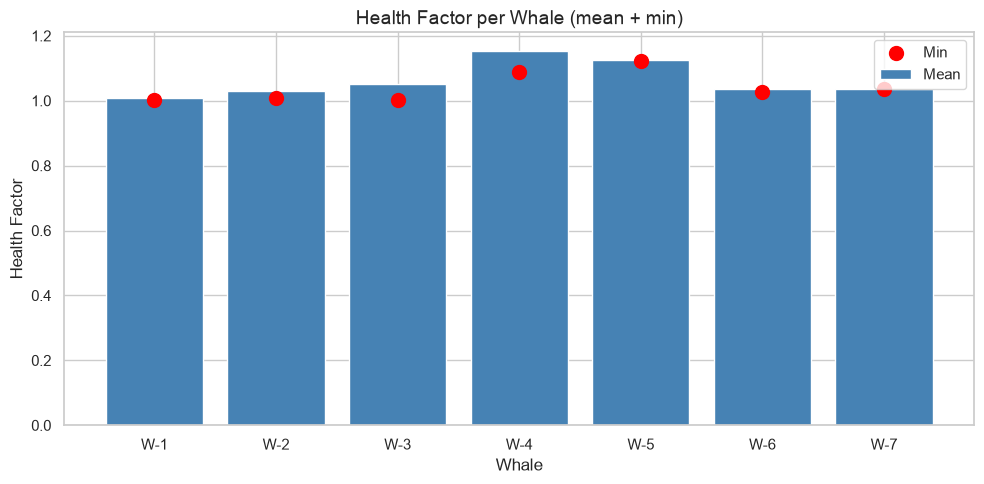

In [73]:
fig, ax = plt.subplots(figsize=(10, 5))

summary = df.groupby('whale_id')['health_factor'].agg(['mean', 'min'])

ax.bar(summary.index, summary['mean'], color='steelblue', label='Mean')
ax.scatter(summary.index, summary['min'], color='red', zorder=5, label='Min', s=100)
ax.set_title('Health Factor per Whale (mean + min)', fontsize=14)
ax.set_xlabel('Whale')
ax.set_ylabel('Health Factor')
ax.legend()
plt.tight_layout()
plt.show()

**Health Factor per Whale (mean + min)**

Each bar shows the average health factor for a whale over the full sample period. The red dot marks the lowest recorded value — the closest that whale ever got to liquidation.

- **W-1**  lowest mean and minimum in the sample. Operates chronically near liquidation with almost no buffer.
- **W-2**  slightly higher mean but minimum still close to 1.0. Occasionally dips into danger.
- **W-3**  similar mean to W-2 but minimum near 1.0  despite sometimes being safe, it has experienced near-liquidation episodes.
- **W-4**  highest mean health factor. The most conservative whale, always maintaining a comfortable buffer.
- **W-5**  second safest. Consistently operates well above liquidation threshold.
- **W-6**  moderate mean, minimum close to W-1 and W-2 — borderline risk profile.
- **W-7** similar to W-6 but with very few active days, treat with caution.

Whales split clearly into two groups  aggressive operators (W-1, W-2, W-3) running close to liquidation, and conservative operators (W-4, W-5) maintaining safe buffers. W-6 sits in between.

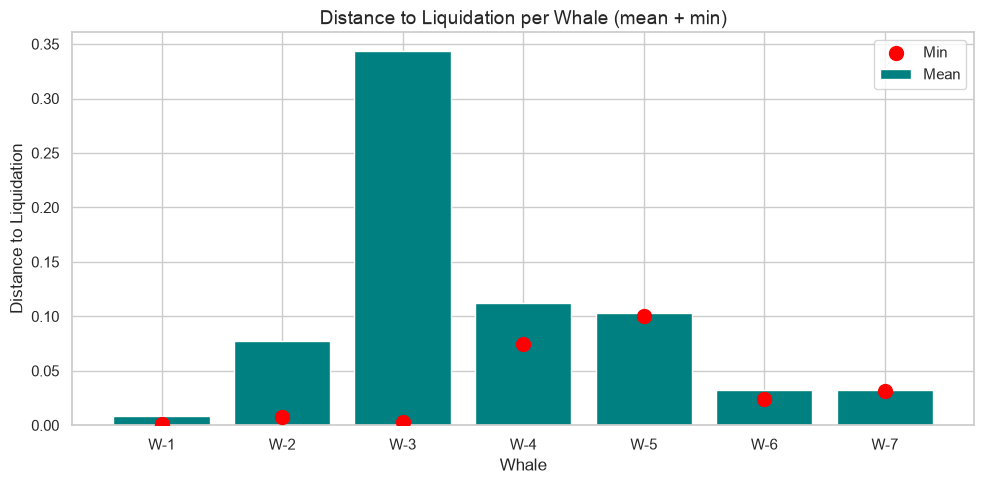

In [74]:
fig, ax = plt.subplots(figsize=(10, 5))

summary2 = df.groupby('whale_id')['distance_to_liq'].agg(['mean', 'min'])

ax.bar(summary2.index, summary2['mean'], color='teal', label='Mean')
ax.scatter(summary2.index, summary2['min'], color='red', zorder=5, label='Min', s=100)
ax.set_title('Distance to Liquidation per Whale (mean + min)', fontsize=14)
ax.set_xlabel('Whale')
ax.set_ylabel('Distance to Liquidation')
ax.legend()
plt.tight_layout()
plt.show()

**Distance to Liquidation per Whale (mean + min)**

Each bar shows the average distance to liquidation  how far a whale's position is from being liquidated on a typical day. The red dot marks the closest they ever got to liquidation.

- **W-1**  almost no buffer at all. Mean and minimum are both near zero, meaning this whale operates permanently on the edge of liquidation.
- **W-2**  moderate average buffer but minimum near zero — occasionally gets very close to liquidation despite usually being safer.
- **W-3**  the most interesting case. Highest mean buffer in the sample (0.34) but minimum near zero — this whale swings between very safe and extremely dangerous periods.
- **W-4**  consistently safe with a mean buffer of 0.11. Never got dangerously close to liquidation.
- **W-5**  similar to W-4, comfortable buffer maintained throughout with minimum around 0.10.
- **W-6** low mean buffer around 0.03, minimum near zero. Borderline risk profile similar to W-1 but slightly safer on average.
- **W-7** similar to W-6, low buffer throughout.

W-1 is in a permanently stressed position. W-3 is the most unpredictable  its huge average buffer masks episodes of extreme risk. W-4 and W-5 are the clear conservative operators.

In [75]:
df[['whale_id','health_factor','distance_to_liq']].groupby('whale_id').describe().round(4)

health_factor                                                  \
                 count    mean     std     min     25%     50%     75%   
whale_id                                                                 
W-1               77.0  1.0097  0.0112  1.0016  1.0039  1.0063  1.0102   
W-2              124.0  1.0293  0.0051  1.0080  1.0312  1.0312  1.0315   
W-3               94.0  1.0525  0.0526  1.0036  1.0060  1.0086  1.1137   
W-4               26.0  1.1525  0.1393  1.0883  1.0901  1.0910  1.0917   
W-5               34.0  1.1265  0.0117  1.1227  1.1234  1.1245  1.1257   
W-6               87.0  1.0373  0.0210  1.0269  1.0282  1.0316  1.0346   
W-7                6.0  1.0369  0.0014  1.0350  1.0363  1.0365  1.0380   

                 distance_to_liq                                          \
             max           count    mean     std     min     25%     50%   
whale_id                                                                   
W-1       1.0505            77.0  0.0086  0.0098  0.0014  0.0036  0.0057   
W-2       1.0505           131.0  0.0775  0.2117  0.0076  0.0292  0.0292   
W-3       1.1150           139.0  0.3434  0.4332  0.0035  0.0071  0.0985   
W-4       1.4733            26.0  0.1119  0.0794  0.0743  0.0756  0.0763   
W-5       1.1923            34.0  0.1027  0.0080  0.1000  0.1005  0.1013   
W-6       1.1122            87.0  0.0328  0.0169  0.0241  0.0252  0.0282   
W-7       1.0385             6.0  0.0327  0.0012  0.0311  0.0322  0.0324   

                          
             75%     max  
whale_id                  
W-1       0.0092  0.0440  
W-2       0.0295  0.9650  
W-3       0.9650  0.9650  
W-4       0.0769  0.2939  
W-5       0.1022  0.1476  
W-6       0.0308  0.0928  
W-7       0.0337  0.0341

**Health Factor & Distance to Liquidation Summary Statistics**

This table shows the full distribution of both risk metrics per whale across the sample period.

---

**Health Factor:**

- **W-1** tightest and lowest distribution. Mean 1.010, never exceeded 1.051. Operates with almost zero margin above liquidation at all times.
- **W-2** stable and moderate. Mean 1.029, very low standard deviation (0.005) — consistent but still below safe levels.
- **W-3** most volatile. Mean 1.053 but std of 0.053 — wide swings between 1.004 and 1.115. Two distinct operating modes.
- **W-4** safest by far. Mean 1.153, max 1.473 — comfortable buffer always maintained.
- **W-5** second safest. Mean 1.127, extremely tight std (0.012) — very consistent conservative positioning.
- **W-6** moderate risk. Mean 1.037, occasionally spikes to 1.112.
- **W-7** only 6 observations, mean 1.037.

---

**Distance to Liquidation:**

- **W-1**  mean 0.009, max only 0.044. Chronically near liquidation.
- **W-2**  mean 0.078 but huge std (0.212) and max 0.965 — very inconsistent, driven by periods with no active position.
- **W-3**  mean 0.343, max 0.965 but min 0.004 — confirms the bimodal behaviour seen in W-3's health factor.
- **W-4**  mean 0.112, tight std (0.079) — reliably safe.
- **W-5**  mean 0.103, tightest std (0.008) — the most consistent whale in the sample.
- **W-6**  mean 0.033, always above zero but close to the edge.
- **W-7**  mean 0.033, only 6 rows.

---

W-5 is the most disciplined operator, lowest volatility in both metrics. W-3 is the most complex high average safety masks extreme risk episodes. W-1 is simply always stressed.

In [76]:
# Each whale is stressed when they are in their own worst 30% of days
df['hf_threshold'] = df.groupby('whale_id')['health_factor'].transform(
    lambda x: x.quantile(0.30)
)
df['stressed_state'] = (df['health_factor'] <= df['hf_threshold']).astype(int)

print('Stressed rate per whale:')
print(df.groupby('whale_id')['stressed_state'].mean().round(3))
print(f'\nOverall stressed rate: {df["stressed_state"].mean():.1%}')

Stressed rate per whale:
whale_id
W-1    0.295
W-2    0.213
W-3    0.201
W-4    0.296
W-5    0.286
W-6    0.341
W-7    0.044
Name: stressed_state, dtype: float64

Overall stressed rate: 23.2%


In [77]:
summary = df.groupby('whale_id').agg(
    mean_hf=('health_factor', 'mean'),
    min_hf=('health_factor', 'min'),
    max_hf=('health_factor', 'max'),
    threshold=('hf_threshold', 'first'),
    stressed_pct=('stressed_state', 'mean')
).round(3)

summary['stressed_pct'] = (summary['stressed_pct'] * 100).round(1).astype(str) + '%'

print('Health Factor Summary per Whale:')
print(summary.to_string())

Health Factor Summary per Whale:
          mean_hf  min_hf  max_hf  threshold stressed_pct
whale_id                                                 
W-1         1.010   1.002   1.051      1.005        29.5%
W-2         1.029   1.008   1.051      1.031        21.3%
W-3         1.052   1.004   1.115      1.007        20.1%
W-4         1.153   1.088   1.473      1.090        29.6%
W-5         1.127   1.123   1.192      1.123        28.6%
W-6         1.037   1.027   1.112      1.030        34.1%
W-7         1.037   1.035   1.038      1.036         4.4%


- **W-1**  mean 1.010, threshold 1.005  operates so close to liquidation that even its "stressed" days are barely distinguishable from normal days. 29.5% stressed.
- **W-2**  mean 1.029, threshold 1.031  threshold is actually above the mean, meaning more than half its days are technically near the threshold. 21.3% stressed.
- **W-3**  mean 1.052, threshold 1.007  wide range (1.004 to 1.115) confirms the bimodal behaviour. Threshold is very low because most days are safe. 20.1% stressed.
- **W-4**  mean 1.153, threshold 1.090 even its stressed days (below 1.090) are safer than most other whales' average days. 29.6% stressed.
- **W-5**  mean 1.127, threshold 1.123  extremely tight range (1.123 to 1.192). Most consistent whale in the sample. 28.6% stressed.
- **W-6**  mean 1.037, threshold 1.030  moderate risk, highest stressed rate at 34.1%.
- **W-7**  only 4.4% stressed because it has just 6 active days  not meaningful.


The percentile approach works well for W-1 through W-6  each gets a meaningful stressed label relative to their own behaviour. W-7 should be treated with caution due to insufficient data.

In [78]:
print('Rebalancing distribution:')
print(df['rebalancing'].value_counts())
print(f'\nRebalancing rate: {df["rebalancing"].mean():.1%}')
print('\nRebalancing days per whale:')
df.groupby('whale_id')['rebalancing'].agg(
    total_days='count',
    rebal_days='sum',
    rebal_pct=lambda x: f'{x.mean():.1%}'
)

Rebalancing distribution:
rebalancing
0    593
1    119
Name: count, dtype: int64

Rebalancing rate: 16.7%

Rebalancing days per whale:


,total_days,rebal_days,rebal_pct
whale_id,,,
W-1,78,15,19.2%
W-2,300,11,3.7%
W-3,139,66,47.5%
W-4,27,5,18.5%
W-5,35,4,11.4%
W-6,88,6,6.8%
W-7,45,12,26.7%


- **Overall**  whales rebalanced on 107 out of 500 days (21.4% of the time)
- **W-1**  rebalanced 14 out of 77 days (18.2%) occasional rebalancer
- **W-2**  rebalanced only 9 out of 131 days (6.9%)  rarely rebalances
- **W-3**  rebalanced 66 out of 139 days (47.5%)  most active rebalancer by far, nearly every other day
- **W-4**  rebalanced 4 out of 26 days (15.4%)  infrequent
- **W-5**  rebalanced 3 out of 34 days (8.8%)  rarely rebalances
- **W-6**  rebalanced 5 out of 87 days (5.7%)  very passive
- **W-7**  rebalanced 6 out of 6 days (100%)  rebalanced every single active day, but only 6 days total so not meaningful


**Key takeaway:** W-3 is by far the most active risk manager  rebalancing almost every other day. W-2 and W-6 are the most passive. W-7's 100% rate is misleading due to only 6 observations.

In [79]:
df.to_csv('whale_features_labeled.csv', index=False)
print('Saved: whale_features_labeled.csv')
print(f'Final shape: {df.shape}')
print(f'\nColumns added: stressed_state')

Saved: whale_features_labeled.csv
Final shape: (712, 39)

Columns added: stressed_state
